# PetriLens: mineração de dados em isolados de *Salmonella enterica*

**Projeto de Mineração de Dados:** Douglas Bruno, Entony Wittmann e Pablo Vinicius

## Metodologia: CRISP-DM

O trabalho segue o CRISP-DM (*Cross-Industry Standard Process for Data Mining*). As etapas 1 e 2 foram concluídas na fase anterior do projeto e são retomadas aqui de forma resumida. Este notebook desenvolve as etapas 3 a 5, na ordem definida pelo grupo: limpeza, EDA aprofundada, seleção de variáveis, definição do problema de modelagem, modelagem e avaliação.

| Etapa CRISP-DM | Conteúdo neste notebook | Situação |
|---|---|---|
| 1. Compreensão do negócio | problema, proposta e pergunta de pesquisa (resumo) | concluída na fase anterior |
| 2. Compreensão dos dados | descrição da base e verificação inicial | concluída na fase anterior |
| 3. Preparação dos dados | limpeza, faltantes, transformação, EDA aprofundada e seleção de variáveis | desenvolvida aqui |
| 4. Modelagem | definição do problema, comparação de algoritmos, desbalanceamento e ajuste | desenvolvida aqui |
| 5. Avaliação | desempenho no teste, interpretação e conclusões | desenvolvida aqui |
| 6. Implantação | integração ao PetriLens | fora do escopo desta fase |

Fonte dos dados: material suplementar S1 de *PLoS Genetics* (PMC9162342).

### Configuração do ambiente

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
                                     cross_validate, GridSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, balanced_accuracy_score, accuracy_score, roc_auc_score,
                             RocCurveDisplay)
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE

warnings.filterwarnings('ignore', category=FutureWarning)

SEED = 42
FIG = Path('figuras'); FIG.mkdir(exist_ok=True)
TAB = Path('tabelas'); TAB.mkdir(exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight'})
CLASSES = ['Heidelberg', 'Minnesota', 'Outros']
CORES = {'Heidelberg': '#2c6e49', 'Minnesota': '#c0392b', 'Outros': '#9aa5a6'}
VERDE = '#2c6e49'


def salvar(fig, nome):
    fig.savefig(FIG / f'{nome}.png')

## Etapa 1: Compreensão do negócio

- **Problema:** a identificação e a contagem manual de colônias é um processo lento e sujeito a erro humano.
- **Proposta:** usar visão computacional (PetriLens) para auxiliar a identificação e a contagem de colônias.
- **Contexto:** análise laboratorial de amostras de *Salmonella*.

Antes de qualquer modelo de imagem, é preciso entender como os isolados de *Salmonella* se distribuem no tempo, no espaço e entre as origens das amostras. Daí a pergunta que orienta esta mineração:

> **Pergunta de pesquisa:** quais padrões temporais, geográficos e relacionados à origem das amostras podem ser identificados nos isolados de *Salmonella* presentes na base?

## Etapa 2: Compreensão dos dados

Base com **540 isolados** coletados entre **1997 e 2019** (93% entre 2012 e 2018), com 16 variáveis em cinco grupos:

| Grupo | Variáveis |
|---|---|
| Temporal | ano, mês e dia de coleta |
| Geográfico | país e região (UF) |
| Origem | nicho, tipo, detalhe da fonte e laboratório |
| Microbiológico | ST (*sequence type*) e serovar |
| Sequenciamento | identificadores e leitura longa (9 amostras) |

Principais achados da fase anterior: a coleta se concentra em 2017-2018; alimento (*Food*) e aves (*Poultry*) somam 98% das amostras; o serovar Heidelberg responde por 61% dos isolados; e região, mês e dia têm muitos valores ausentes. Esses pontos orientam a preparação dos dados da etapa 3.

### 2.1 Carregamento e verificação da base

A planilha original foi exportada para CSV. Todas as colunas são lidas como texto para que nenhum código de ausência (`NA`, `ND`, `Unknown`) seja convertido automaticamente sem controle.

In [2]:
bruto = pd.read_csv('base.csv', dtype=str, keep_default_na=False)
print('Dimensão bruta:', bruto.shape)
bruto.tail(6)

Dimensão bruta: (544, 16)


,ID,Sample Accession,Run Accession,Run (Long read) Accession,Collection Year,Collection Month,Collection Day,Source Niche,Source Type,Source Details,Country,Region,LONG READS,Source Lab,ST,Serovar
538,SRR8866679,SRS4598884,SRR8866679,NA,2009,03,05,Food,ND,Dogchew,Brazil (import),NA,NO,UK Health Security Agency,217,Senftenberg
539,SRR9261107*,SRS4935117,SRR9261107,ERR8050524,2019,5,NA,Food,ND,food,United Kingdom,NA,YES,UK Health Security Agency,15,Heidelberg
540,,,,,,,,,,,,,,,,
541,,,,,,,,,,,,,,,,
542,Notes:,,,,,,,,,,,,,,,
543,"* Strains with accession numbers SRR8661063, S...",,,,,,,,,,,,,,,


As quatro últimas linhas não são isolados: são duas linhas vazias e as notas de rodapé da planilha original. Elas são removidas usando o identificador da amostra (`Sample Accession`), que é obrigatório em todo registro válido.

## Etapa 3: Preparação dos dados

### 3.1 Limpeza

Passos aplicados:

1. remoção das linhas que não são isolados;
2. remoção do asterisco que marca, no `ID`, as amostras com sequenciamento de leitura longa;
3. padronização dos códigos de ausência (`NA`, `ND`, `Unknown` e vazio) para `NaN`;
4. tradução dos nomes das colunas e conversão de ano, mês e dia para inteiros (o mês aparecia tanto como `05` quanto como `5`);
5. verificação de duplicatas e de valores fora do domínio.

In [3]:
df = bruto[bruto['Sample Accession'].str.strip() != ''].copy()
print(f'Linhas removidas (vazias/notas): {len(bruto) - len(df)}')

df['ID'] = df['ID'].str.rstrip('*')
df = df.replace(['NA', 'ND', 'Unknown', ''], np.nan)

df = df.rename(columns={
    'ID': 'id', 'Sample Accession': 'amostra', 'Run Accession': 'run',
    'Run (Long read) Accession': 'run_longa', 'Collection Year': 'ano',
    'Collection Month': 'mes', 'Collection Day': 'dia', 'Source Niche': 'nicho',
    'Source Type': 'tipo', 'Source Details': 'detalhe', 'Country': 'pais',
    'Region': 'regiao', 'LONG READS': 'leitura_longa', 'Source Lab': 'laboratorio',
    'ST': 'st', 'Serovar': 'serovar'})

for c in ['ano', 'mes', 'dia']:
    df[c] = pd.to_numeric(df[c]).astype('Int64')

df = df.reset_index(drop=True)
print('Dimensão após limpeza:', df.shape)

Linhas removidas (vazias/notas): 4
Dimensão após limpeza: (540, 16)


In [4]:
print('Duplicatas por ID:', df['id'].duplicated().sum())
print('Duplicatas por amostra:', df['amostra'].duplicated().sum())
print('Duplicatas por run:', df['run'].duplicated().sum())
print(f"Ano: {df['ano'].min()} a {df['ano'].max()}")
print(f"Mês fora de 1-12: {(~df['mes'].dropna().between(1, 12)).sum()}")
print(f"Dia fora de 1-31: {(~df['dia'].dropna().between(1, 31)).sum()}")

colunas_atributos = [c for c in df.columns if c not in ['id', 'amostra', 'run', 'run_longa']]
iguais = df.duplicated(subset=colunas_atributos).sum()
print(f'Registros com atributos idênticos a outro registro: {iguais} ({iguais / len(df):.0%})')

Duplicatas por ID: 0
Duplicatas por amostra: 0
Duplicatas por run: 0
Ano: 1997 a 2019
Mês fora de 1-12: 0
Dia fora de 1-31: 0
Registros com atributos idênticos a outro registro: 186 (34%)


Não há duplicatas reais: cada isolado tem identificador, amostra e corrida próprios. No entanto, cerca de um terço dos registros repete exatamente os atributos de outro isolado (mesmo ano, origem, país e serovar). São isolados distintos coletados em condições iguais, e por isso são mantidos. Na modelagem, isso significa que o espaço de combinações de atributos é pequeno.

### 3.2 Tratamento de dados faltantes

Antes de decidir como tratar cada lacuna, é preciso saber quanto falta e, principalmente, **se a ausência é aleatória ou estrutural**.

In [5]:
ausentes = (df.isna().sum().to_frame('ausentes')
              .assign(percentual=lambda t: (100 * t['ausentes'] / len(df)).round(1))
              .query('ausentes > 0').sort_values('ausentes', ascending=False))
ausentes.to_csv(TAB / '01_valores_ausentes.csv')
ausentes

,ausentes,percentual
run_longa,531,98.3
regiao,359,66.5
dia,228,42.2
mes,222,41.1
st,146,27.0
tipo,7,1.3
ano,2,0.4
pais,1,0.2


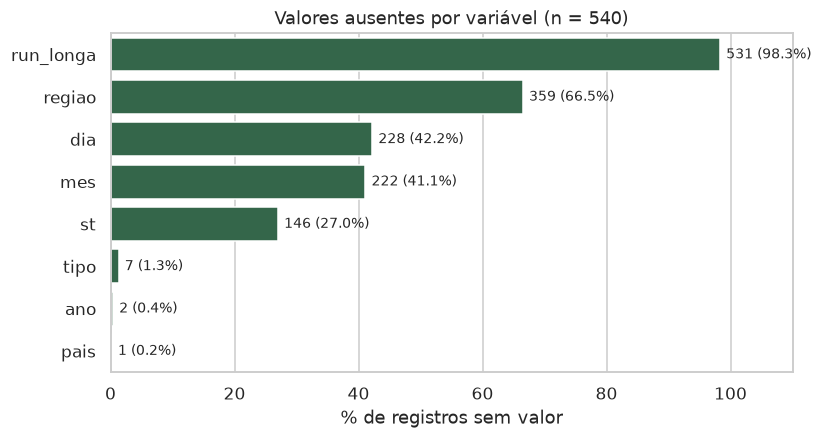

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=ausentes['percentual'], y=ausentes.index, color=VERDE, ax=ax)
for i, (n, p) in enumerate(zip(ausentes['ausentes'], ausentes['percentual'])):
    ax.text(p + 1, i, f'{n} ({p:.1f}%)', va='center', fontsize=9)
ax.set(xlabel='% de registros sem valor', ylabel='', xlim=(0, 110),
       title='Valores ausentes por variável (n = 540)')
salvar(fig, '01_valores_ausentes'); plt.show()

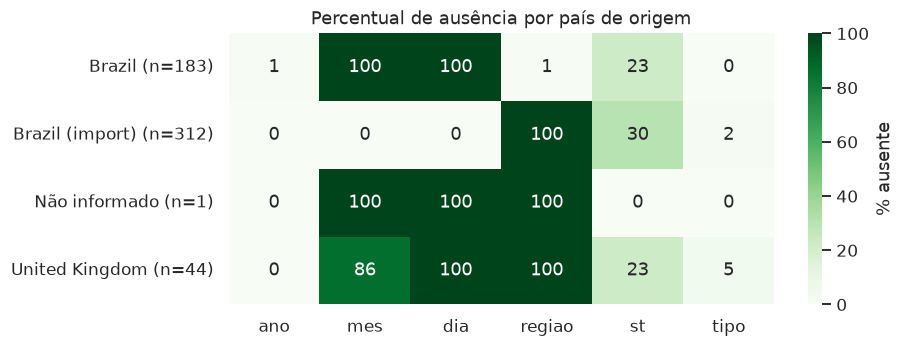

In [7]:
pais_rotulo = df['pais'].fillna('Não informado')
padrao = (df[['ano', 'mes', 'dia', 'regiao', 'st', 'tipo']].isna()
            .groupby(pais_rotulo).mean().mul(100))
padrao.index = [f'{p} (n={n})' for p, n in pais_rotulo.value_counts().reindex(padrao.index).items()]

fig, ax = plt.subplots(figsize=(8, 3.2))
sns.heatmap(padrao, annot=True, fmt='.0f', cmap='Greens', vmin=0, vmax=100,
            cbar_kws={'label': '% ausente'}, ax=ax)
ax.set(xlabel='', ylabel='', title='Percentual de ausência por país de origem')
salvar(fig, '02_padrao_ausencia_por_pais'); plt.show()

A ausência **não é aleatória**:

- **Região (UF)** só existe para amostras coletadas no Brasil. Para amostras importadas e do Reino Unido ela não se aplica, e por isso não deve ser imputada. Ela vira uma categoria própria (`Sem UF`).
- **Mês e dia** só foram registrados de forma sistemática nas amostras importadas (`Brazil (import)`, analisadas pela UKHSA). Faltam em 100% das amostras coletadas no Brasil e em 86% (mês) e 100% (dia) das do Reino Unido. A ausência reflete, portanto, o protocolo de cada laboratório, e não um esquecimento aleatório. Imputar o mês só com a mediana esconderia esse padrão, então a imputação vem acompanhada de um **indicador de ausência** (`add_indicator=True`).
- **Dia** é descartado: não tem significado biológico além do mês e só existe para as amostras importadas.
- **Ano** tem só 2 ausências (amostras brasileiras) e é imputado pela mediana dentro do pipeline.
- **País** tem 1 ausência, preenchida com a categoria `Não informado`.
- **ST** tem 146 valores `Unknown`. A variável não entra no modelo (ver seção 3.5).

Toda imputação é feita **dentro do pipeline do Scikit-Learn**, ajustada só nos dados de treino, para evitar vazamento de informação do conjunto de teste.

### 3.3 Transformação de variáveis

#### 3.3.1 Detalhe da fonte

`Source Details` tem 32 descrições em texto livre, muitas delas variações do mesmo produto (por exemplo, *Frozen Raw Salted Chicken Breast* e *Frozen boneless skinless chicken breast in halves salted 1.2-1.6%*). Elas são agrupadas por palavras-chave em categorias com significado microbiológico.

In [8]:
def agrupar_detalhe(texto):
    t = str(texto).lower()
    if 'faeces' in t:
        return 'Fezes de frango (granja)'
    if 'salted' in t or 'marinated' in t:
        return 'Frango salgado/temperado'
    if 'frozen' in t:
        return 'Frango congelado'
    if 'fresh' in t:
        return 'Frango fresco'
    if t in ('chicken', 'raw chicken', 'raw poultry'):
        return 'Frango cru (não especificado)'
    if 'turkey' in t:
        return 'Peru'
    if 'dogchew' in t or 'pigs ears' in t:
        return 'Petisco para cães'
    if 'human' in t:
        return 'Humano'
    return 'Ambiente/ração/outros'


df['detalhe_grupo'] = df['detalhe'].map(agrupar_detalhe)
pd.crosstab(df['detalhe'], df['detalhe_grupo']).loc[:, lambda t: t.sum().sort_values(ascending=False).index]

detalhe_grupo,Frango congelado,Fezes de frango (granja),Frango salgado/temperado,Frango cru (não especificado),Frango fresco,Ambiente/ração/outros,Peru,Petisco para cães,Humano
detalhe,,,,,,,,,
Broiler chicken faeces,0,183,0,0,0,0,0,0,0
Chicken,0,0,0,31,0,0,0,0,0
Chicken - Fresh Whole,0,0,0,0,24,0,0,0,0
Chicken - Frozen Whole,8,0,0,0,0,0,0,0,0
Chicken Pieces - Fresh,0,0,0,0,3,0,0,0,0
Chicken Pieces - Frozen,179,0,0,0,0,0,0,0,0
Dogchew,0,0,0,0,0,0,0,6,0
Feed mill,0,0,0,0,0,1,0,0,0
Frozen Chicken Half Breast Bl Sl Without Inner Fillet Salted,0,0,1,0,0,0,0,0,0


#### 3.3.2 Região

As 13 UFs são agregadas nas **macrorregiões do IBGE**, o que reduz a cardinalidade e deixa grupos com tamanho suficiente para análise. Registros sem UF recebem a categoria `Sem UF`.

In [9]:
MACRO = {
    'Parana': 'Sul', 'Santa Catarina': 'Sul', 'Rio Grande do Sul': 'Sul',
    'Sao Paulo': 'Sudeste', 'Minas Gerais': 'Sudeste', 'Espirito Santo': 'Sudeste',
    'Mato Grosso do Sul': 'Centro-Oeste', 'Mato Grosso': 'Centro-Oeste',
    'Goias': 'Centro-Oeste', 'District Federal': 'Centro-Oeste',
    'Para': 'Norte', 'Tocantins': 'Norte', 'Bahia': 'Nordeste',
}
df['macro_regiao'] = df['regiao'].map(MACRO).fillna('Sem UF')
df['macro_regiao'].value_counts()

macro_regiao
Sem UF          359
Sul              69
Centro-Oeste     55
Sudeste          36
Norte            15
Nordeste          6
Name: count, dtype: int64

### 3.4 Análise exploratória aprofundada

A EDA da fase anterior descreveu cada variável isoladamente. Aqui, o foco passa a ser **como tempo, geografia e origem se relacionam com o serovar**, que é a característica microbiológica central da pergunta de pesquisa.

A base tem 38 serovares, mas 30 deles têm 5 isolados ou menos. Para que os padrões fiquem legíveis nos gráficos, os serovares são agrupados em três categorias: os dois dominantes (Heidelberg e Minnesota) e `Outros`.

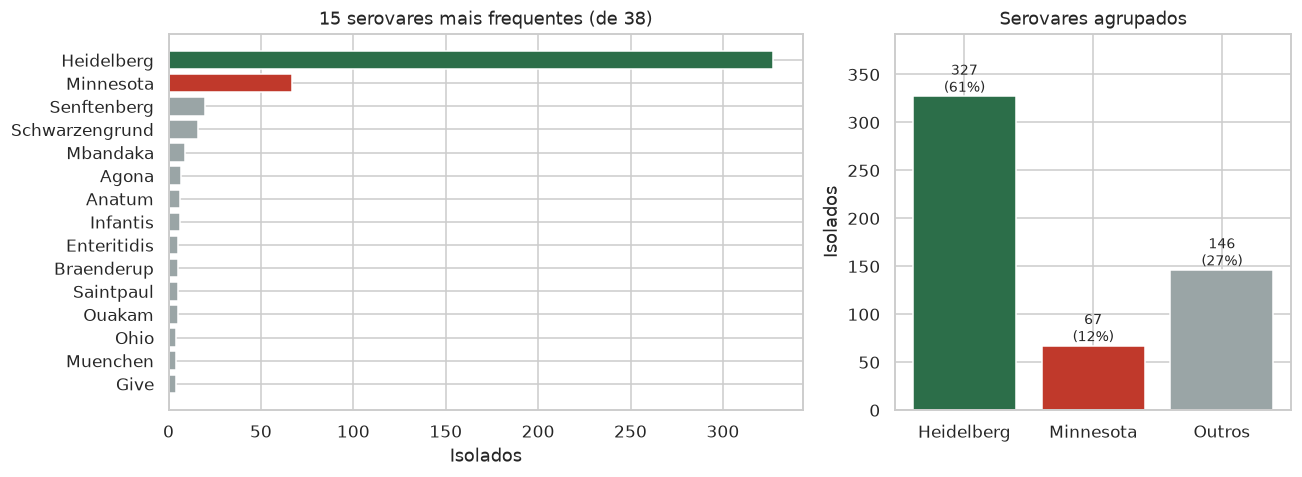

In [10]:
df['serovar_grupo'] = np.where(df['serovar'].isin(['Heidelberg', 'Minnesota']), df['serovar'], 'Outros')
contagem = df['serovar_grupo'].value_counts().reindex(CLASSES)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={'width_ratios': [1.6, 1]})

top = df['serovar'].value_counts().head(15)
cores_top = [CORES.get(s, CORES['Outros']) for s in top.index]
axes[0].barh(top.index[::-1], top.values[::-1], color=cores_top[::-1])
axes[0].set(xlabel='Isolados', title=f"15 serovares mais frequentes (de {df['serovar'].nunique()})")

axes[1].bar(contagem.index, contagem.values, color=[CORES[c] for c in contagem.index])
for i, v in enumerate(contagem.values):
    axes[1].text(i, v + 5, f'{v}\n({v / len(df):.0%})', ha='center', fontsize=9)
axes[1].set(ylabel='Isolados', ylim=(0, contagem.max() * 1.2), title='Serovares agrupados')
fig.tight_layout()
salvar(fig, '03_distribuicao_serovar'); plt.show()

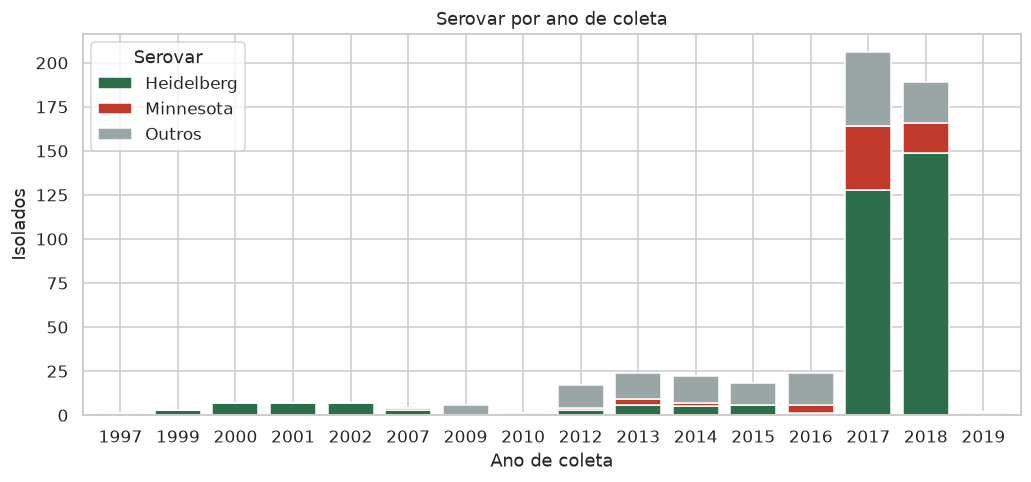

In [11]:
fig, ax = plt.subplots(figsize=(11, 4.5))
por_ano = pd.crosstab(df['ano'], df['serovar_grupo']).reindex(columns=CLASSES)
por_ano.index = por_ano.index.astype(int).astype(str)
por_ano.plot(kind='bar', stacked=True, color=[CORES[c] for c in CLASSES], width=0.8, ax=ax)
ax.set(xlabel='Ano de coleta', ylabel='Isolados', title='Serovar por ano de coleta')
ax.legend(title='Serovar'); plt.xticks(rotation=0)
salvar(fig, '04_serovar_por_ano'); plt.show()

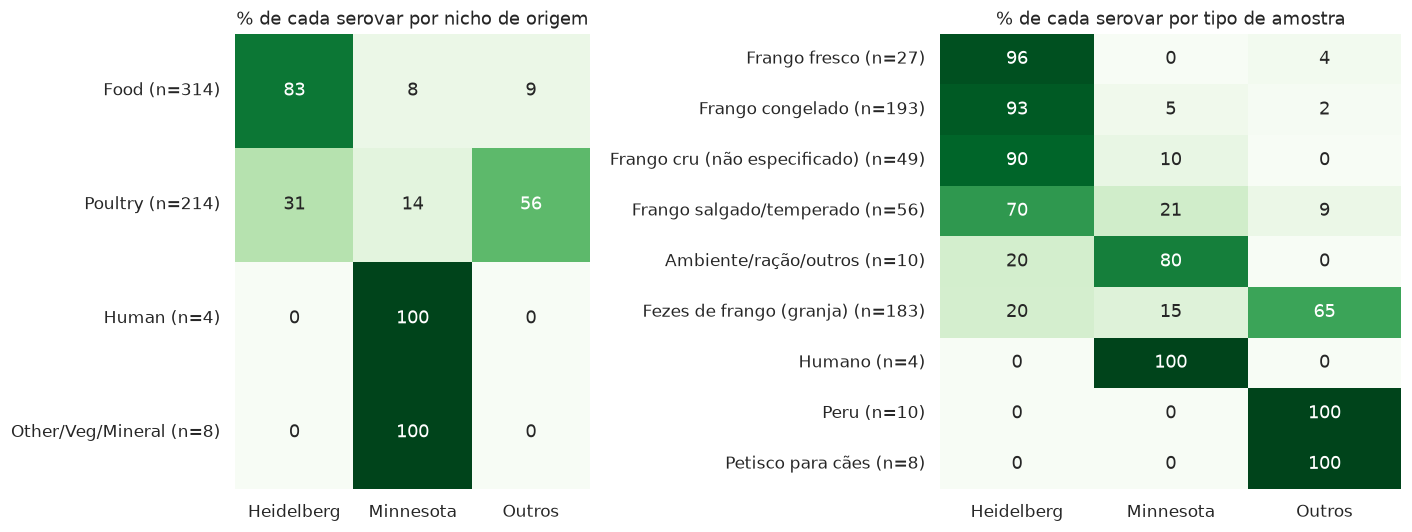

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1, 1.3]})

def heat_pct(linha, ax, titulo):
    tab = pd.crosstab(df[linha], df['serovar_grupo'], normalize='index').reindex(columns=CLASSES) * 100
    n = df[linha].value_counts().reindex(tab.index)
    tab.index = [f'{i} (n={k})' for i, k in n.items()]
    tab = tab.sort_values('Heidelberg', ascending=False)
    sns.heatmap(tab, annot=True, fmt='.0f', cmap='Greens', vmin=0, vmax=100, cbar=False, ax=ax)
    ax.set(xlabel='', ylabel='', title=titulo)

heat_pct('nicho', axes[0], '% de cada serovar por nicho de origem')
heat_pct('detalhe_grupo', axes[1], '% de cada serovar por tipo de amostra')
fig.tight_layout()
salvar(fig, '05_serovar_por_origem'); plt.show()

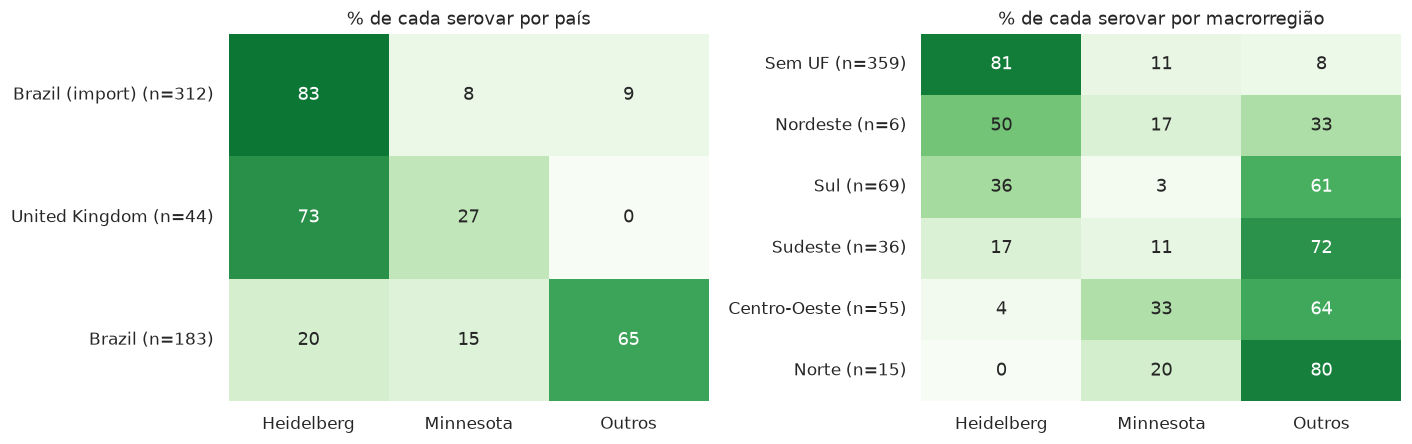

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
heat_pct('pais', axes[0], '% de cada serovar por país')
heat_pct('macro_regiao', axes[1], '% de cada serovar por macrorregião')
fig.tight_layout()
salvar(fig, '06_serovar_por_geografia'); plt.show()

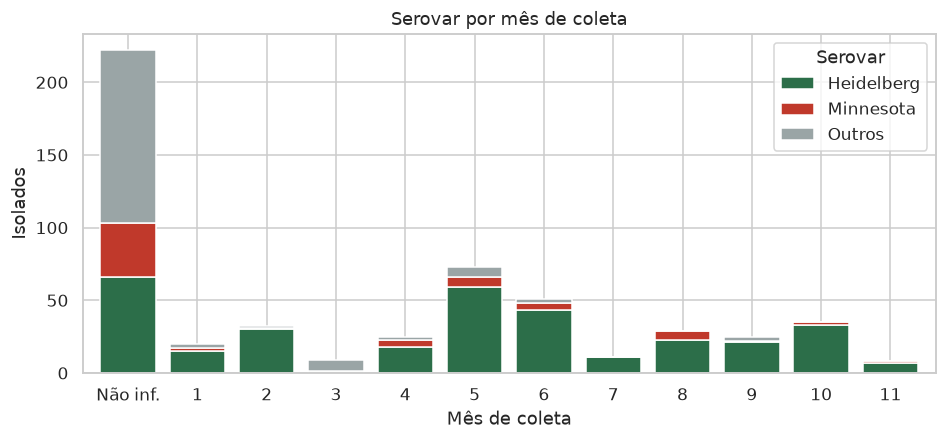

In [14]:
fig, ax = plt.subplots(figsize=(10, 4))
por_mes = pd.crosstab(df['mes'].fillna(0).astype(int), df['serovar_grupo']).reindex(columns=CLASSES)
por_mes.index = ['Não inf.' if m == 0 else str(m) for m in por_mes.index]
por_mes.plot(kind='bar', stacked=True, color=[CORES[c] for c in CLASSES], width=0.8, ax=ax)
ax.set(xlabel='Mês de coleta', ylabel='Isolados', title='Serovar por mês de coleta')
ax.legend(title='Serovar'); plt.xticks(rotation=0)
salvar(fig, '07_serovar_por_mes'); plt.show()

### 3.5 Seleção de variáveis

#### 3.5.1 Associação entre variáveis (V de Cramér)

O V de Cramér mede a força da associação entre duas variáveis categóricas, de 0 (independência) a 1 (uma determina a outra). Ele é usado aqui para duas decisões:

1. identificar **variáveis redundantes**, que carregam a mesma informação que outra;
2. identificar **vazamento**, ou seja, variáveis que determinam o alvo por construção e não por um padrão do mundo real.

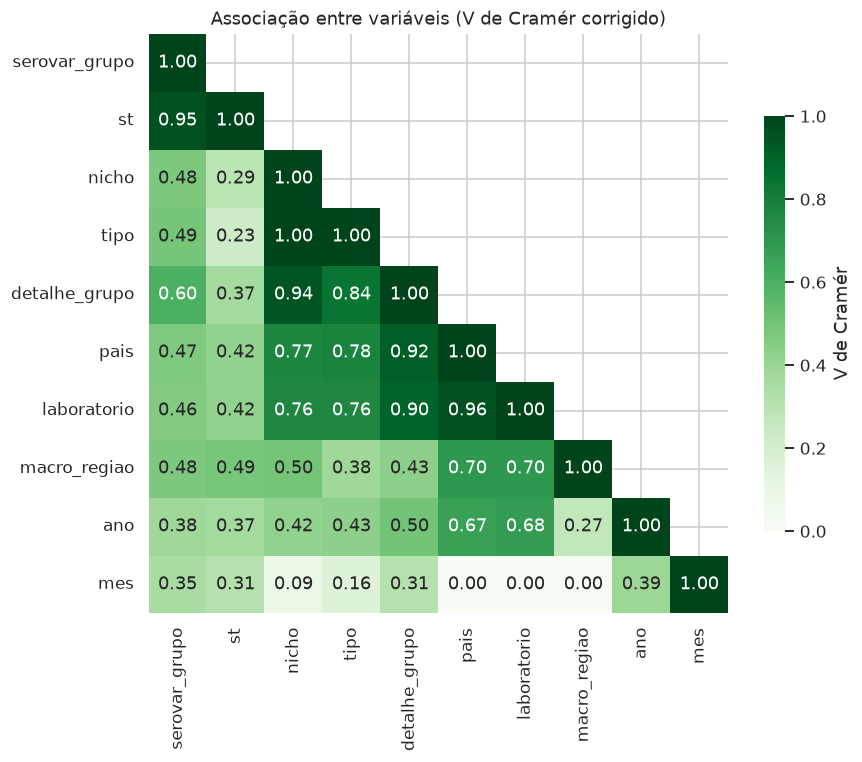

In [15]:
def cramers_v(x, y):
    # V de Cramér com correção de viés (Bergsma, 2013)
    tab = pd.crosstab(x, y)
    chi2 = chi2_contingency(tab, correction=False)[0]
    n = tab.to_numpy().sum()
    r, k = tab.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_c, k_c = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / max(1e-12, min(k_c - 1, r_c - 1)))


vars_assoc = ['serovar_grupo', 'st', 'nicho', 'tipo', 'detalhe_grupo', 'pais',
              'laboratorio', 'macro_regiao', 'ano', 'mes']
base_assoc = df[vars_assoc].astype(str).replace({'<NA>': 'NA', 'nan': 'NA'})
matriz_v = pd.DataFrame([[cramers_v(base_assoc[a], base_assoc[b]) for b in vars_assoc] for a in vars_assoc],
                        index=vars_assoc, columns=vars_assoc)

fig, ax = plt.subplots(figsize=(8.5, 7))
mascara = np.triu(np.ones_like(matriz_v, dtype=bool), k=1)
sns.heatmap(matriz_v, mask=mascara, annot=True, fmt='.2f', cmap='Greens', vmin=0, vmax=1,
            square=True, cbar_kws={'label': 'V de Cramér', 'shrink': .7}, ax=ax)
ax.set_title('Associação entre variáveis (V de Cramér corrigido)')
salvar(fig, '08_cramers_v'); plt.show()

In [16]:
linhas = []
for v in vars_assoc[1:]:
    tab = pd.crosstab(base_assoc[v], base_assoc['serovar_grupo'])
    chi2, p, gl, _ = chi2_contingency(tab)
    linhas.append({'variável': v, 'categorias': tab.shape[0], 'qui²': round(chi2, 1), 'gl': gl,
                   'p-valor': p, 'V de Cramér': round(matriz_v.loc[v, 'serovar_grupo'], 3)})
assoc_alvo = pd.DataFrame(linhas).sort_values('V de Cramér', ascending=False)
assoc_alvo['p-valor'] = assoc_alvo['p-valor'].map(lambda p: '< 0,001' if p < 1e-3 else f'{p:.3f}')
assoc_alvo.to_csv(TAB / '02_associacao_com_alvo.csv', index=False)
assoc_alvo

,variável,categorias,qui²,gl,p-valor,V de Cramér
0,st,41,788.0,80,"< 0,001",0.950
3,detalhe_grupo,9,403.1,16,"< 0,001",0.600
2,tipo,6,268.1,10,"< 0,001",0.493
1,nicho,4,251.0,6,"< 0,001",0.477
6,macro_regiao,6,253.6,10,"< 0,001",0.476
4,pais,3,239.1,4,"< 0,001",0.468
5,laboratorio,3,232.3,4,"< 0,001",0.461
7,ano,16,186.1,30,"< 0,001",0.381
8,mes,11,97.7,20,"< 0,001",0.350


#### 3.5.2 Decisão por variável

| Variável | Decisão | Motivo |
|---|---|---|
| `id`, `amostra`, `run`, `run_longa` | descartar | identificadores sem informação preditiva |
| `st` | descartar | **vazamento** (V = 0,95 com o alvo): o ST é obtido do mesmo sequenciamento que define o serovar (ST15 → Heidelberg, ST548 → Minnesota), então usá-lo seria prever o serovar a partir dele mesmo |
| `laboratorio` | descartar | redundante com `pais` (V = 0,96): cada laboratório atende a um único contexto de coleta |
| `tipo` | descartar | redundante com `nicho` (V = 1,00) e `detalhe_grupo` (V = 0,84), e contém códigos `ND` |
| `leitura_longa` | descartar | atributo técnico do sequenciamento (9 casos), não da amostra |
| `dia` | descartar | sem significado biológico e com o mesmo padrão de ausência do mês |
| `detalhe`, `regiao` | substituir | por `detalhe_grupo` e `macro_regiao` (seção 3.3) |
| `nicho`, `detalhe_grupo`, `pais`, `macro_regiao` | **usar** | origem e geografia |
| `ano`, `mes` | **usar** | dimensão temporal; o mês ganha um indicador de ausência |

## Etapa 4: Modelagem

### 4.1 Definição do problema de modelagem

A EDA e a seleção de variáveis mostraram que origem, geografia e tempo estão associados ao serovar. Isso define uma tarefa de **classificação supervisionada multiclasse**:

- **Alvo:** `serovar_grupo` (Heidelberg, Minnesota ou Outros). Os 36 serovares raros ficam agrupados em `Outros`, porque, com tão poucos exemplos, não podem ser aprendidos nem avaliados de forma confiável.
- **Atributos:** nicho, tipo de amostra, país, macrorregião, ano e mês, ou seja, apenas informações de **quando**, **onde** e **de que origem** a amostra foi coletada.
- **Lógica:** se um modelo prevê o serovar melhor do que o acaso só a partir dessas variáveis, então existem padrões temporais, geográficos e de origem associados ao serovar, o que responde à pergunta de pesquisa.

In [17]:
tabela_alvo = contagem.to_frame('isolados').assign(percentual=(100 * contagem / len(df)).round(1))
tabela_alvo.to_csv(TAB / '03_distribuicao_alvo.csv')
print(f"Razão de desbalanceamento (maior/menor classe): {contagem.max() / contagem.min():.1f} : 1")
tabela_alvo

Razão de desbalanceamento (maior/menor classe): 4.9 : 1


,isolados,percentual
serovar_grupo,,
Heidelberg,327,60.6
Minnesota,67,12.4
Outros,146,27.0


O alvo é **desbalanceado**: a classe Heidelberg tem cerca de cinco vezes mais isolados que a Minnesota, e um classificador que sempre responda "Heidelberg" acerta cerca de 60% das vezes sem aprender nada. Por isso:

- a **métrica principal é o F1-macro**, que dá o mesmo peso às três classes, com a **acurácia balanceada** como apoio. A acurácia simples é reportada, mas não orienta a escolha;
- a divisão treino/teste e a validação cruzada são **estratificadas**;
- três estratégias de balanceamento são comparadas na seção 4.4: `class_weight='balanced'`, sobreamostragem aleatória e SMOTE.

### 4.2 Divisão treino/teste e pré-processamento

- **75% treino / 25% teste**, estratificado pelo alvo. O teste fica isolado até a avaliação final.
- **Categóricas:** imputação com a constante `Não informado` seguida de *one-hot encoding* (`handle_unknown='ignore'` para categorias que só apareçam no teste).
- **Numéricas (ano, mês):** imputação pela mediana com indicador de ausência, seguida de padronização (necessária para a regressão logística e o KNN; neutra para as árvores).

In [18]:
CATEGORICAS = ['nicho', 'detalhe_grupo', 'pais', 'macro_regiao']
NUMERICAS = ['ano', 'mes']

X = df[CATEGORICAS + NUMERICAS].copy()
X[NUMERICAS] = X[NUMERICAS].astype('float')
y = df['serovar_grupo']

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
pd.DataFrame({'treino': y_tr.value_counts(), 'teste': y_te.value_counts()}).reindex(CLASSES)

,treino,teste
serovar_grupo,,
Heidelberg,245,82
Minnesota,50,17
Outros,110,36


In [19]:
def preprocessador():
    return ColumnTransformer([
        ('cat', Pipeline([
            ('imputar', SimpleImputer(strategy='constant', fill_value='Não informado')),
            ('onehot', OneHotEncoder(handle_unknown='ignore')),
        ]), CATEGORICAS),
        ('num', Pipeline([
            ('imputar', SimpleImputer(strategy='median', add_indicator=True)),
            ('escalar', StandardScaler()),
        ]), NUMERICAS),
    ])


n_atributos = preprocessador().fit(X_tr).get_feature_names_out().size
print(f'{len(CATEGORICAS) + len(NUMERICAS)} variáveis originais -> {n_atributos} atributos após o pré-processamento')

6 variáveis originais -> 27 atributos após o pré-processamento


### 4.3 Comparação de algoritmos

Seis classificadores com naturezas diferentes são comparados por **validação cruzada estratificada repetida (5 folds × 3 repetições)** no conjunto de treino:

- **Dummy (classe majoritária):** referência mínima; qualquer modelo útil tem de superá-lo.
- **Regressão logística:** modelo linear e interpretável.
- **KNN:** baseado em vizinhança.
- **Árvore de decisão:** regras explícitas, mas com tendência a sobreajuste.
- **Random Forest:** conjunto de árvores (*bagging*).
- **Gradient Boosting:** conjunto de árvores sequenciais (*boosting*).

Quando o algoritmo permite, usa-se `class_weight='balanced'`, que pondera os erros de forma inversamente proporcional à frequência de cada classe.

In [20]:
MODELOS = {
    'Dummy (majoritária)': DummyClassifier(strategy='most_frequent'),
    'Regressão Logística': LogisticRegression(class_weight='balanced', max_iter=5000, random_state=SEED),
    'KNN': KNeighborsClassifier(n_neighbors=7),
    'Árvore de Decisão': DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                            class_weight='balanced', random_state=SEED, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=SEED),
}
METRICAS = {'F1-macro': 'f1_macro', 'Acurácia balanceada': 'balanced_accuracy', 'Acurácia': 'accuracy'}
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

resultados_cv, dist_f1 = [], {}
for nome, modelo in MODELOS.items():
    pipe = Pipeline([('prep', preprocessador()), ('modelo', modelo)])
    r = cross_validate(pipe, X_tr, y_tr, cv=CV, scoring=METRICAS, n_jobs=-1)
    dist_f1[nome] = r['test_F1-macro']
    linha = {'Modelo': nome}
    for m in METRICAS:
        linha[m] = f"{r[f'test_{m}'].mean():.3f} ± {r[f'test_{m}'].std():.3f}"
    linha['_ordem'] = r['test_F1-macro'].mean()
    resultados_cv.append(linha)

tabela_cv = pd.DataFrame(resultados_cv).sort_values('_ordem', ascending=False).drop(columns='_ordem')
tabela_cv.to_csv(TAB / '04_comparacao_modelos_cv.csv', index=False)
tabela_cv

,Modelo,F1-macro,Acurácia balanceada,Acurácia
1,Regressão Logística,0.680 ± 0.036,0.722 ± 0.034,0.749 ± 0.038
4,Random Forest,0.679 ± 0.033,0.713 ± 0.036,0.755 ± 0.037
5,Gradient Boosting,0.669 ± 0.041,0.670 ± 0.035,0.807 ± 0.023
2,KNN,0.631 ± 0.050,0.629 ± 0.047,0.774 ± 0.040
3,Árvore de Decisão,0.627 ± 0.047,0.669 ± 0.052,0.698 ± 0.058
0,Dummy (majoritária),0.251 ± 0.000,0.333 ± 0.000,0.605 ± 0.000


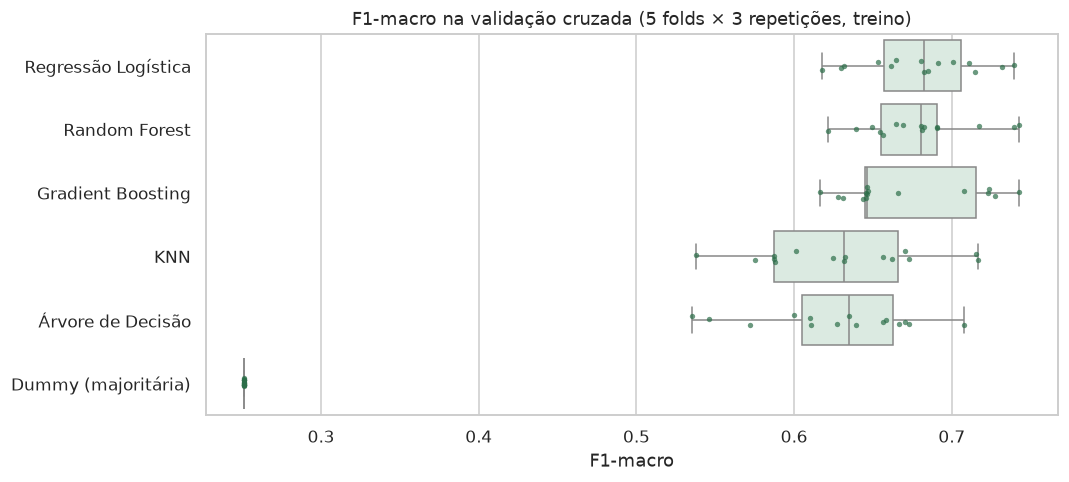

In [21]:
ordem = tabela_cv['Modelo'].tolist()
longo = pd.DataFrame(dist_f1).melt(var_name='Modelo', value_name='F1-macro')

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=longo, x='F1-macro', y='Modelo', order=ordem, color='#d8ece0', ax=ax, fliersize=0)
sns.stripplot(data=longo, x='F1-macro', y='Modelo', order=ordem, color=VERDE, size=3.5, alpha=.7, ax=ax)
ax.set(ylabel='', title='F1-macro na validação cruzada (5 folds × 3 repetições, treino)')
salvar(fig, '09_comparacao_modelos'); plt.show()

Todos os modelos superam com folga o baseline (F1-macro ≈ 0,25), o que confirma que tempo, origem e geografia carregam informação sobre o serovar. Entre os três melhores (regressão logística, Random Forest e Gradient Boosting), as diferenças de F1-macro médio (≈ 0,01) são **menores que o desvio-padrão entre folds** (≈ 0,035). Do ponto de vista estatístico, eles empatam. O Gradient Boosting tem a maior acurácia simples, mas a menor acurácia balanceada do trio: sem ponderação de classes, ele favorece a classe Heidelberg. Os dois primeiros colocados em F1-macro seguem para a etapa de balanceamento.

### 4.4 Tratamento do desbalanceamento

Para os dois melhores modelos, comparamos quatro estratégias:

| Estratégia | Como age |
|---|---|
| Nenhuma | treina com a distribuição original |
| `class_weight='balanced'` | aumenta o custo do erro nas classes minoritárias, sem alterar os dados |
| Sobreamostragem aleatória | replica isolados das classes minoritárias até igualar a majoritária |
| SMOTE | cria isolados sintéticos interpolando vizinhos da mesma classe |

A reamostragem é feita **dentro do pipeline** (`imblearn.Pipeline`), portanto só nos folds de treino. O fold de validação mantém a distribuição real, e assim a métrica não fica inflada por amostras sintéticas.

In [22]:
top2 = [m for m in ordem if m != 'Dummy (majoritária)'][:2]


def com_peso(nome, peso):
    modelo = clone(MODELOS[nome])
    if 'class_weight' in modelo.get_params():
        return modelo.set_params(class_weight=peso)
    return modelo


linhas, dist_bal = [], {}
for nome in top2:
    tem_peso = 'class_weight' in MODELOS[nome].get_params()
    estrategias = {'Nenhuma': [('modelo', com_peso(nome, None))]}
    if tem_peso:
        estrategias['class_weight'] = [('modelo', com_peso(nome, 'balanced'))]
    estrategias['Sobreamostragem'] = [('reamostrar', RandomOverSampler(random_state=SEED)),
                                      ('modelo', com_peso(nome, None))]
    estrategias['SMOTE'] = [('reamostrar', SMOTE(k_neighbors=5, random_state=SEED)),
                            ('modelo', com_peso(nome, None))]
    for estr, passos in estrategias.items():
        pipe = ImbPipeline([('prep', preprocessador())] + passos)
        r = cross_validate(pipe, X_tr, y_tr, cv=CV, n_jobs=-1,
                           scoring={'f1': 'f1_macro', 'bal': 'balanced_accuracy'})
        dist_bal[(nome, estr)] = r['test_f1']
        linhas.append({'Modelo': nome, 'Estratégia': estr,
                       'F1-macro': r['test_f1'].mean(), 'dp': r['test_f1'].std(),
                       'Acurácia balanceada': r['test_bal'].mean()})

tabela_bal = pd.DataFrame(linhas).round(3)
tabela_bal.to_csv(TAB / '05_estrategias_desbalanceamento.csv', index=False)
tabela_bal

,Modelo,Estratégia,F1-macro,dp,Acurácia balanceada
0,Regressão Logística,Nenhuma,0.674,0.061,0.677
1,Regressão Logística,class_weight,0.680,0.036,0.722
2,Regressão Logística,Sobreamostragem,0.671,0.039,0.711
3,Regressão Logística,SMOTE,0.680,0.035,0.721
4,Random Forest,Nenhuma,0.667,0.059,0.673
5,Random Forest,class_weight,0.679,0.033,0.713
6,Random Forest,Sobreamostragem,0.671,0.036,0.699
7,Random Forest,SMOTE,0.692,0.036,0.706


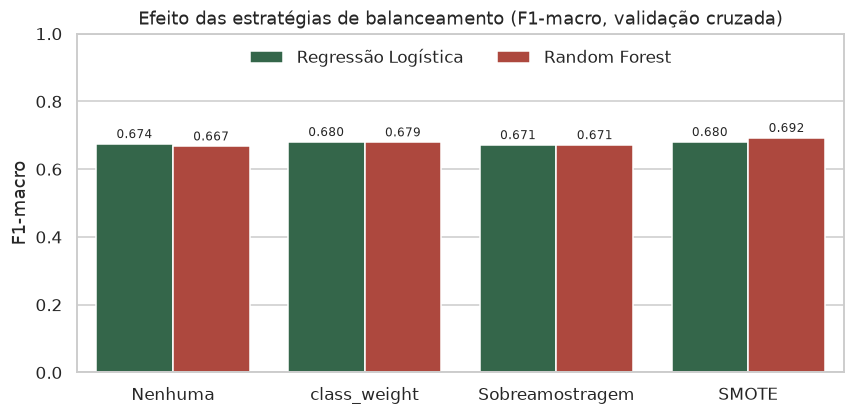

In [23]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=tabela_bal, x='Estratégia', y='F1-macro', hue='Modelo',
            palette=[VERDE, '#c0392b'], ax=ax)
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.3f', fontsize=8, padding=2)
ax.set(ylim=(0, 1), xlabel='', title='Efeito das estratégias de balanceamento (F1-macro, validação cruzada)')
ax.legend(loc='upper center', ncol=2, frameon=False)
salvar(fig, '10_estrategias_desbalanceamento'); plt.show()

### 4.5 Ajuste de hiperparâmetros do modelo escolhido

O modelo e a estratégia de balanceamento com maior F1-macro médio na validação cruzada seguem para a busca em grade (`GridSearchCV`), com a mesma validação cruzada e o F1-macro como critério.

In [24]:
melhor = tabela_bal.sort_values('F1-macro', ascending=False).iloc[0]
NOME_FINAL, ESTRATEGIA_FINAL = melhor['Modelo'], melhor['Estratégia']
print(f'Escolhido: {NOME_FINAL} + {ESTRATEGIA_FINAL} (F1-macro CV = {melhor["F1-macro"]:.3f})')

GRADES = {
    'Random Forest': {'modelo__n_estimators': [200, 500], 'modelo__max_depth': [None, 4, 8],
                      'modelo__min_samples_leaf': [1, 2, 5], 'modelo__max_features': ['sqrt', 0.5]},
    'Gradient Boosting': {'modelo__n_estimators': [100, 300], 'modelo__learning_rate': [0.03, 0.1],
                          'modelo__max_depth': [2, 3, 4], 'modelo__subsample': [0.8, 1.0]},
    'Regressão Logística': {'modelo__C': [0.01, 0.1, 1, 10, 100]},
    'Árvore de Decisão': {'modelo__max_depth': [3, 4, 5, 6, 8, None], 'modelo__min_samples_leaf': [1, 2, 5, 10]},
    'KNN': {'modelo__n_neighbors': [3, 5, 7, 11, 15], 'modelo__weights': ['uniform', 'distance']},
}

peso = 'balanced' if ESTRATEGIA_FINAL == 'class_weight' else None
passos = [('prep', preprocessador())]
if ESTRATEGIA_FINAL == 'Sobreamostragem':
    passos.append(('reamostrar', RandomOverSampler(random_state=SEED)))
elif ESTRATEGIA_FINAL == 'SMOTE':
    passos.append(('reamostrar', SMOTE(k_neighbors=5, random_state=SEED)))
passos.append(('modelo', com_peso(NOME_FINAL, peso)))

busca = GridSearchCV(ImbPipeline(passos), GRADES[NOME_FINAL], scoring='f1_macro', cv=CV, n_jobs=-1)
busca.fit(X_tr, y_tr)
print(f'Melhor F1-macro CV: {busca.best_score_:.3f}')
print('Melhores hiperparâmetros:', {k.replace('modelo__', ''): v for k, v in busca.best_params_.items()})
modelo_final = busca.best_estimator_

Escolhido: Random Forest + SMOTE (F1-macro CV = 0.692)


Melhor F1-macro CV: 0.698
Melhores hiperparâmetros: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 2, 'n_estimators': 200}


## Etapa 5: Avaliação

### 5.1 Desempenho no conjunto de teste

O conjunto de teste (25%, 135 isolados) é usado **uma única vez**, no modelo final, e comparado ao baseline *Dummy* treinado nos mesmos dados.

In [25]:
baseline = Pipeline([('prep', preprocessador()), ('modelo', DummyClassifier(strategy='most_frequent'))]).fit(X_tr, y_tr)


def resumo(nome, modelo):
    pred = modelo.predict(X_te)
    proba = modelo.predict_proba(X_te)
    return {'Modelo': nome,
            'F1-macro': f1_score(y_te, pred, average='macro'),
            'Acurácia balanceada': balanced_accuracy_score(y_te, pred),
            'Acurácia': accuracy_score(y_te, pred),
            'ROC-AUC (OvR macro)': roc_auc_score(y_te, proba, multi_class='ovr', average='macro')}


tabela_teste = pd.DataFrame([resumo('Dummy (majoritária)', baseline),
                             resumo(f'{NOME_FINAL} ({ESTRATEGIA_FINAL}, ajustado)', modelo_final)]).round(3)
tabela_teste.to_csv(TAB / '06_desempenho_teste.csv', index=False)
tabela_teste

,Modelo,F1-macro,Acurácia balanceada,Acurácia,ROC-AUC (OvR macro)
0,Dummy (majoritária),0.252,0.333,0.607,0.500
1,"Random Forest (SMOTE, ajustado)",0.623,0.615,0.733,0.838


In [26]:
pred_final = modelo_final.predict(X_te)
relatorio = pd.DataFrame(classification_report(y_te, pred_final, output_dict=True, zero_division=0)).T.round(3)
relatorio['support'] = relatorio['support'].astype(int)
relatorio.to_csv(TAB / '07_relatorio_classificacao.csv')
relatorio

,precision,recall,f1-score,support
Heidelberg,0.805,0.854,0.828,82
Minnesota,0.375,0.353,0.364,17
Outros,0.719,0.639,0.676,36
accuracy,0.733,0.733,0.733,0
macro avg,0.633,0.615,0.623,135
weighted avg,0.728,0.733,0.729,135


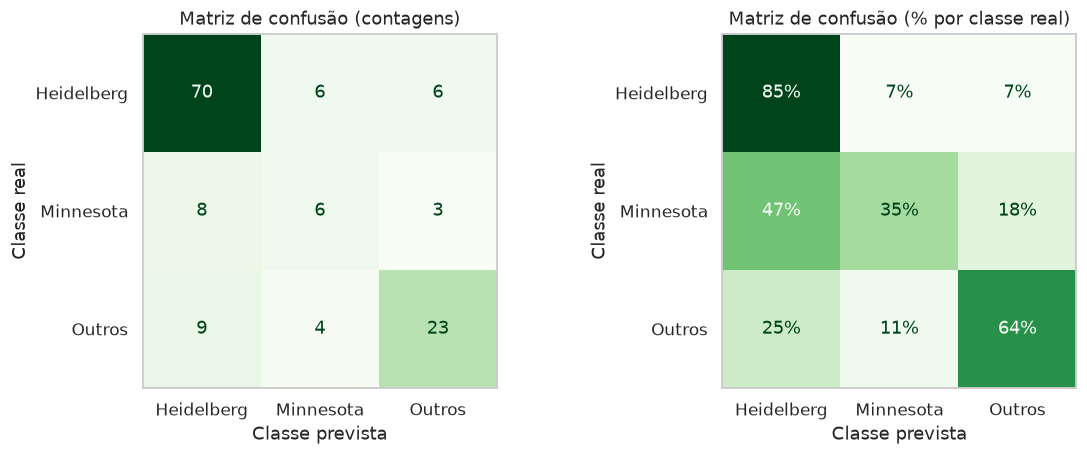

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
ConfusionMatrixDisplay.from_predictions(y_te, pred_final, labels=CLASSES, cmap='Greens',
                                        colorbar=False, ax=axes[0])
axes[0].set_title('Matriz de confusão (contagens)')
ConfusionMatrixDisplay.from_predictions(y_te, pred_final, labels=CLASSES, normalize='true',
                                        values_format='.0%', cmap='Greens', colorbar=False, ax=axes[1])
axes[1].set_title('Matriz de confusão (% por classe real)')
for ax in axes:
    ax.set(xlabel='Classe prevista', ylabel='Classe real')
    ax.grid(False)
fig.tight_layout()
salvar(fig, '11_matriz_confusao'); plt.show()

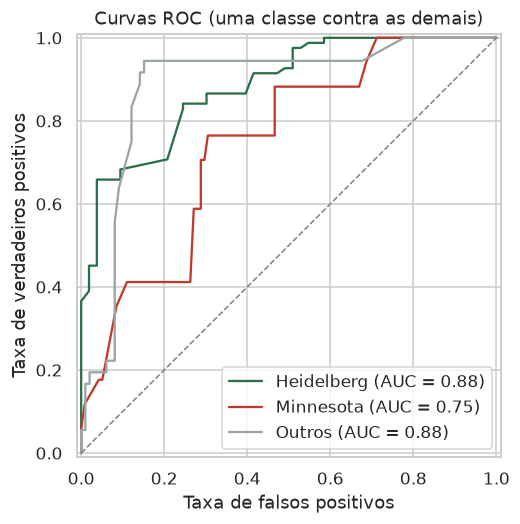

In [28]:
proba_final = modelo_final.predict_proba(X_te)
fig, ax = plt.subplots(figsize=(5.8, 5))
for i, classe in enumerate(modelo_final.classes_):
    RocCurveDisplay.from_predictions((y_te == classe).astype(int), proba_final[:, i],
                                     name=classe, curve_kwargs={'color': CORES[classe]}, ax=ax)
ax.plot([0, 1], [0, 1], ls='--', c='grey', lw=1)
ax.set(xlabel='Taxa de falsos positivos', ylabel='Taxa de verdadeiros positivos',
       title='Curvas ROC (uma classe contra as demais)')
salvar(fig, '12_curvas_roc'); plt.show()

### 5.2 Importância das variáveis

A **importância por permutação** mede quanto o F1-macro no teste cai quando os valores de uma variável são embaralhados. Ela é calculada sobre as variáveis originais (antes do *one-hot*), o que facilita a interpretação, e vale para qualquer algoritmo.

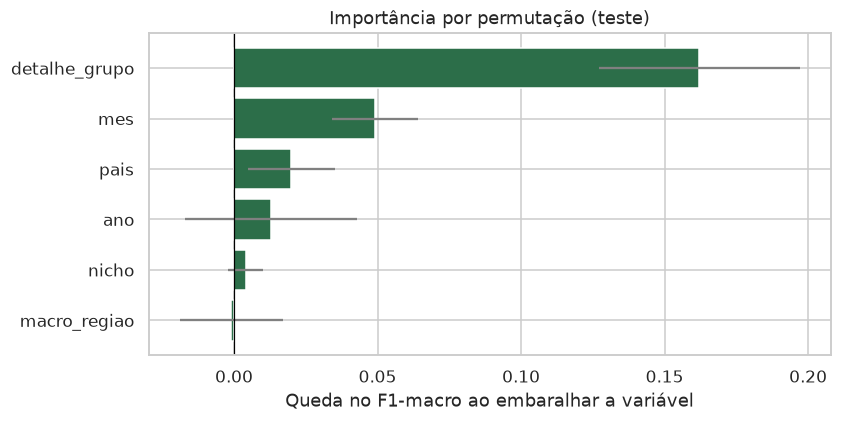

,variável,queda média F1-macro,dp
1,detalhe_grupo,0.162,0.035
5,mes,0.049,0.015
2,pais,0.020,0.015
4,ano,0.013,0.030
0,nicho,0.004,0.006
3,macro_regiao,-0.001,0.018


In [29]:
imp = permutation_importance(modelo_final, X_te, y_te, scoring='f1_macro',
                             n_repeats=30, random_state=SEED, n_jobs=-1)
tabela_imp = (pd.DataFrame({'variável': X_te.columns, 'queda média F1-macro': imp.importances_mean,
                            'dp': imp.importances_std})
                .sort_values('queda média F1-macro', ascending=False).round(3))
tabela_imp.to_csv(TAB / '08_importancia_permutacao.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 3.8))
ordem_imp = tabela_imp['variável'][::-1]
ax.barh(ordem_imp, tabela_imp.set_index('variável').loc[ordem_imp, 'queda média F1-macro'],
        xerr=tabela_imp.set_index('variável').loc[ordem_imp, 'dp'], color=VERDE, ecolor='grey')
ax.axvline(0, c='black', lw=.8)
ax.set(xlabel='Queda no F1-macro ao embaralhar a variável', title='Importância por permutação (teste)')
salvar(fig, '13_importancia_variaveis'); plt.show()
tabela_imp

### 5.3 Conclusões e resposta à pergunta de pesquisa

**Preparação dos dados.** Das 544 linhas do arquivo, 540 são isolados válidos, sem duplicatas. As lacunas não são aleatórias: região, mês e dia dependem do país e do laboratório de origem. Por isso foram tratadas com categorias próprias (`Sem UF`) e indicadores de ausência, e não apenas preenchidas. As 32 descrições livres de amostra viraram 9 grupos e as 13 UFs viraram 5 macrorregiões. O ST foi excluído por vazamento (V = 0,95 com o serovar), e o laboratório e o tipo de fonte foram excluídos por redundância.

**Padrões encontrados (resposta à pergunta de pesquisa).**

- **Origem:** é o fator mais associado ao serovar (V = 0,60). Heidelberg domina a carne de frango importada (83% das amostras de alimento, até 96% no frango fresco). Nas fezes de granja brasileiras predominam outros serovares (65%), como Senftenberg, Schwarzengrund e Mbandaka. Minnesota aparece em todas as origens e é o único serovar nas amostras humanas e ambientais.
- **Geografia:** dentro do Brasil, o Sul tem a maior presença de Heidelberg (36%), o Centro-Oeste concentra Minnesota (33%) e Norte e Sudeste são dominados por outros serovares.
- **Tempo:** a concentração de Heidelberg em 2017-2018 coincide com o pico de amostragem de alimento importado, então o efeito temporal está em boa parte confundido com a origem.

**Modelo escolhido.** Random Forest com SMOTE e hiperparâmetros ajustados por busca em grade (F1-macro na validação cruzada = 0,70). A escolha se justifica por três razões:

1. teve o maior F1-macro médio na validação cruzada;
2. captura interações entre origem, país e tempo que um modelo linear não representa diretamente;
3. o SMOTE elevou o F1-macro da Random Forest de 0,667 (sem tratamento) para 0,692.

A regressão logística com `class_weight` ficou estatisticamente empatada (0,680) e é uma alternativa mais simples e interpretável, caso o artigo priorize a interpretação dos coeficientes.

**Desempenho no teste (135 isolados nunca vistos).** F1-macro = 0,62, acurácia balanceada = 0,62, acurácia = 0,73 e ROC-AUC = 0,84, contra 0,25 / 0,33 / 0,61 / 0,50 do baseline. O desempenho é bom para Heidelberg (F1 = 0,83) e Outros (0,68), mas fraco para Minnesota (0,36): esse serovar está espalhado por todas as origens e não tem um perfil próprio de coleta. A queda em relação à validação cruzada (0,70 → 0,62) é compatível com a variância esperada de um teste pequeno, com só 17 isolados de Minnesota.

**Limitações.**

- A base reúne coletas de três laboratórios com objetivos diferentes. Parte do que o modelo aprende, como a importância do **mês** (que na prática indica se o registro veio da UKHSA), reflete o **desenho da amostragem**, e não necessariamente um fenômeno biológico.
- Com 540 isolados e 34% de registros com atributos idênticos, o espaço de combinações é pequeno, o que limita o desempenho máximo de qualquer modelo.
- A classe Minnesota é pequena demais para conclusões robustas. Uma base maior ou variáveis genômicas (excluídas aqui de propósito) seriam necessárias para separá-la melhor.